# Red Neuronal Siamesa, Embeddings y Triplet Loss con PyTorch

Práctica reproducible en Google Colab. Rostros sintéticos → Tripletas → Encoder CNN → Triplet Loss → One-shot / Few-shot / Verificación por distancia.

## Paso 1. Preparar el entorno: importar librerías

In [1]:
import math
import random
import os
import itertools
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

## Paso 2. Fijar la semilla y seleccionar CPU o GPU

In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print('PyTorch:', torch.__version__)
print('Dispositivo:', DEVICE)

PyTorch: 2.11.0+cpu
Dispositivo: cpu


## Paso 3. Crear una función que genere rostros sintéticos

In [3]:
def synthetic_face(identity, variant, size=64):
    rng = random.Random(identity * 1000 + variant)
    img = Image.new('L', (size, size), color=230)
    d = ImageDraw.Draw(img)

    params = [
        (18, 20, 10, 42, 0),
        (16, 22, 12, 40, 1),
        (20, 18, 9, 44, 2),
        (17, 19, 13, 41, 3),
    ]
    eye_dx, eye_y, eye_r, mouth_y, style = params[identity % 4]
    jx = rng.randint(-2, 2)
    jy = rng.randint(-2, 2)

    d.ellipse(
        (10+jx, 7+jy, 54+jx, 59+jy),
        fill=185 + identity*10, outline=60, width=2
    )

    cx = 32 + jx
    ey = eye_y + jy
    for ex in (cx-eye_dx//2, cx+eye_dx//2):
        d.ellipse(
            (ex-eye_r//4, ey-eye_r//4,
             ex+eye_r//4, ey+eye_r//4),
            fill=30
        )
    d.line(
        (cx, ey+4, cx-2, ey+14, cx+2, ey+14),
        fill=70,
        width=2
    )
    if style % 2 == 0:
        d.arc(
            (20+jx, mouth_y-6+jy, 44+jx, mouth_y+8+jy),
            start=10, end=170, fill=40, width=2
        )
    else:
        d.arc(
            (20+jx, mouth_y-2+jy, 44+jx, mouth_y+12+jy),
            start=190, end=350, fill=40, width=2
        )
    if style == 1:
        d.line((18+jx, 15+jy, 46+jx, 15+jy), fill=40, width=3)
    if style == 2:
        d.ellipse((24+jx, 44+jy, 40+jx, 49+jy), outline=40, width=2)
    if style == 3:
        d.line((15+jx, 28+jy, 49+jx, 28+jy), fill=90, width=1)

    arr = np.array(img, dtype=np.float32)
    noise = np.random.default_rng(
        identity*100 + variant
    ).normal(0, 3, arr.shape)
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)
    return arr

## Paso 4. Generar el dataset sintético

In [4]:
N_ID = 4
N_VAR = 12

images = []
labels = []

for identity in range(N_ID):
    for variant in range(N_VAR):
        images.append(synthetic_face(identity, variant))
        labels.append(identity)

images = np.stack(images)
labels = np.array(labels)

print('Imágenes:', images.shape)
print('Etiquetas:', labels.shape)

Imágenes: (48, 64, 64)
Etiquetas: (48,)


## Paso 5. Visualizar el dataset (4 identidades × variantes)

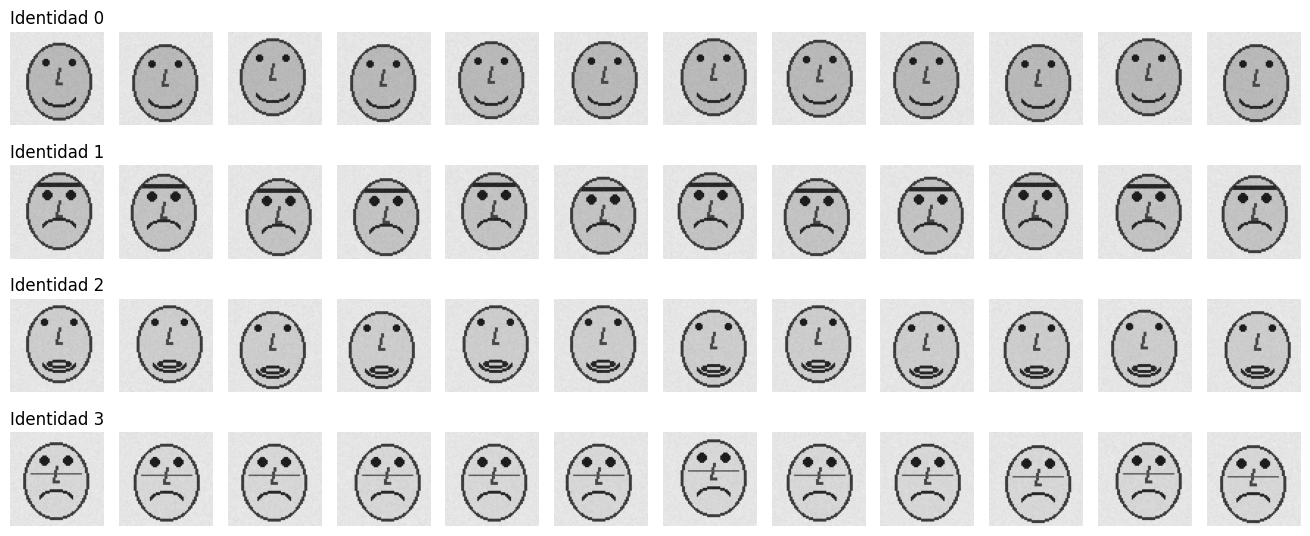

In [5]:
fig, axes = plt.subplots(
    N_ID, N_VAR,
    figsize=(N_VAR*1.1, N_ID*1.4)
)
for i in range(N_ID):
    for j in range(N_VAR):
        k = i * N_VAR + j
        axes[i, j].imshow(
            images[k],
            cmap='gray',
            vmin=0,
            vmax=255
        )
        axes[i, j].axis('off')
        if j == 0:
            axes[i, j].set_title(f'Identidad {i}')
plt.tight_layout()
plt.show()

## Paso 6. Convertir las imágenes a tensores de PyTorch

In [6]:
X = torch.tensor(images, dtype=torch.float32)
X = X.unsqueeze(1) / 255.0
y = torch.tensor(labels, dtype=torch.long)

print('X:', X.shape)
print('y:', y.shape)
print('Rango X:', float(X.min()), float(X.max()))

X: torch.Size([48, 1, 64, 64])
y: torch.Size([48])
Rango X: 0.0784313753247261 0.9450980424880981


## Paso 7. Crear el Dataset de tripletas Anchor-Positive-Negative

In [7]:
class TripletFaces(Dataset):
    def __init__(self, X, y, triplets_per_epoch=400):
        self.X = X
        self.y = y
        self.n = triplets_per_epoch
        self.by_class = {
            int(c): torch.where(y == c)[0].tolist()
            for c in torch.unique(y)
        }
        self.classes = list(self.by_class)

    def __len__(self):
        return self.n

    def __getitem__(self, idx):
        anchor_class = random.choice(self.classes)
        negative_class = random.choice(
            [c for c in self.classes if c != anchor_class]
        )
        anchor_idx, positive_idx = random.sample(
            self.by_class[anchor_class], 2
        )
        negative_idx = random.choice(
            self.by_class[negative_class]
        )
        return (
            self.X[anchor_idx],
            self.X[positive_idx],
            self.X[negative_idx],
            anchor_class,
            negative_class
        )

## Paso 8. Construir el dataset y visualizar una tripleta

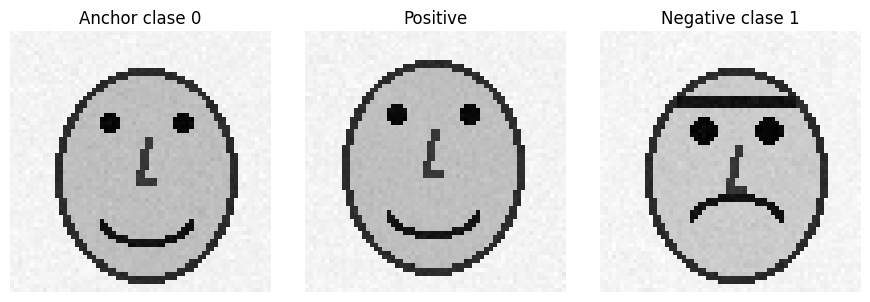

In [8]:
trip = TripletFaces(X, y, triplets_per_epoch=400)

a, p, n, ca, cn = trip[0]

fig, ax = plt.subplots(1, 3, figsize=(9, 3))
for tensor_img, title, axis in [
    (a, f'Anchor clase {ca}', ax[0]),
    (p, 'Positive', ax[1]),
    (n, f'Negative clase {cn}', ax[2])
]:
    axis.imshow(tensor_img.squeeze(), cmap='gray')
    axis.set_title(title)
    axis.axis('off')
plt.tight_layout()
plt.show()

## Paso 9. Construir el encoder de embeddings

In [9]:
class Encoder(nn.Module):
    def __init__(self, emb_dim=64):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.ffc = nn.Linear(32 * 4 * 4, emb_dim)

    def forward(self, x):
        z = self.features(x)
        z = z.flatten(1)
        z = self.ffc(z)
        z = F.normalize(z, p=2, dim=1)
        return z

## Paso 10. Instanciar el encoder y probar un embedding

In [10]:
model = Encoder(emb_dim=64).to(DEVICE)

with torch.no_grad():
    sample = X[:5].to(DEVICE)
    emb = model(sample)

print('Embedding shape:', emb.shape)
print('Norma del primer embedding:', float(emb[0].norm()))

Embedding shape: torch.Size([5, 64])
Norma del primer embedding: 1.0


## Paso 11. Preparar DataLoader, Triplet Loss y optimizador

In [11]:
loader = DataLoader(
    trip,
    batch_size=32,
    shuffle=True
)
criterion = nn.TripletMarginLoss(
    margin=0.8,
    p=2
)
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3
)

## Paso 12. Entrenar el modelo con Triplet Loss

In [12]:
losses = []
for epoch in range(18):
    model.train()
    total = 0
    count = 0
    for a, p, n, _, _ in loader:
        a = a.to(DEVICE)
        p = p.to(DEVICE)
        n = n.to(DEVICE)

        za = model(a)
        zp = model(p)
        zn = model(n)

        loss = criterion(za, zp, zn)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item() * a.size(0)
        count += a.size(0)

    mean_loss = total / count
    losses.append(mean_loss)

    if epoch in [0, 1, 2, 5, 10, 17]:
        print(f'Época {epoch+1:02d} | loss={mean_loss:.4f}')

Época 01 | loss=0.3981
Época 02 | loss=0.0266
Época 03 | loss=0.0024
Época 06 | loss=0.0000
Época 11 | loss=0.0002
Época 18 | loss=0.0000


## Paso 13. Graficar la evolución de Triplet Loss

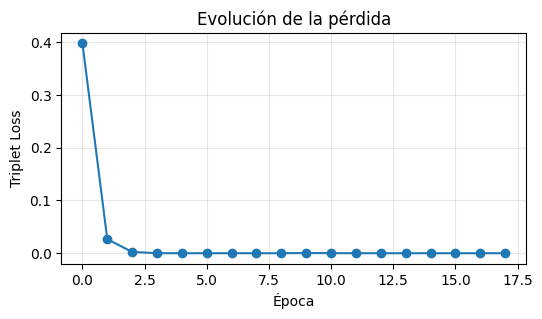

In [13]:
plt.figure(figsize=(6, 3))
plt.plot(losses, marker='o')
plt.xlabel('Época')
plt.ylabel('Triplet Loss')
plt.title('Evolución de la pérdida')
plt.grid(alpha=0.3)
plt.show()

## Paso 14. Calcular embeddings y distancias positivas/negativas

In [14]:
model.eval()
with torch.no_grad():
    Z = model(X.to(DEVICE)).cpu()

pos = []
neg = []
for c in range(N_ID):
    idxs = np.where(labels == c)[0]
    for i in range(len(idxs)):
        for j in range(i+1, len(idxs)):
            pos.append(
                torch.dist(Z[idxs[i]], Z[idxs[j]]).item()
            )
    for c2 in range(c+1, N_ID):
        idxs2 = np.where(labels == c2)[0]
        for i in idxs:
            for j in idxs2:
                neg.append(
                    torch.dist(Z[i], Z[j]).item()
                )

pos = np.array(pos)
neg = np.array(neg)

print('Distancia positiva media:', round(float(pos.mean()), 4))
print('Distancia negativa media:', round(float(neg.mean()), 4))

Distancia positiva media: 0.1312
Distancia negativa media: 1.5421


## Paso 15. Histograma de distancias

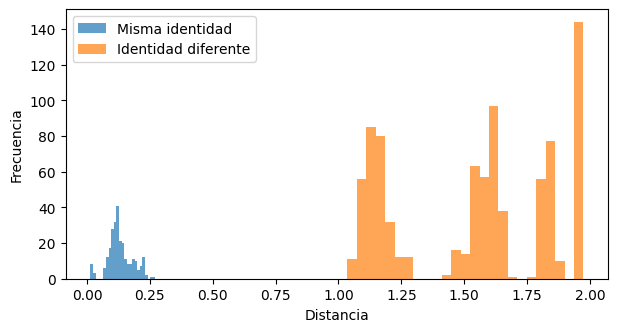

In [15]:
plt.figure(figsize=(7, 3.5))
plt.hist(pos, bins=25, alpha=0.7, label='Misma identidad')
plt.hist(neg, bins=25, alpha=0.7, label='Identidad diferente')
plt.xlabel('Distancia')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

## Paso 16. Implementar One-shot Learning

In [16]:
refs = {
    c: np.where(labels == c)[0][0]
    for c in range(N_ID)
}

queries = [
    i for i in range(len(X))
    if i not in refs.values()
]

correct = 0
for i in queries:
    dists = {
        c: torch.dist(Z[i], Z[idx]).item()
        for c, idx in refs.items()
    }
    pred = min(dists, key=dists.get)
    correct += int(pred == labels[i])

acc_one = correct / len(queries)
print(
    'Accuracy One-shot:',
    round(acc_one, 4),
    f'({correct}/{len(queries)})'
)

Accuracy One-shot: 1.0 (44/44)


## Paso 17. Implementar Few-shot Learning

In [17]:
ref_ids = {
    c: np.where(labels == c)[0][:3]
    for c in range(N_ID)
}

prototypes = {}
for c, idx in ref_ids.items():
    proto = Z[idx].mean(0, keepdim=True)
    proto = F.normalize(proto, p=2, dim=1)
    prototypes[c] = proto.squeeze(0)

query_ids = {
    i for i in range(len(X))
    if all(i not in ids for ids in ref_ids.values())
}

correct = 0
for i in query_ids:
    dists = {
        c: torch.dist(Z[i], proto).item()
        for c, proto in prototypes.items()
    }
    pred = min(dists, key=dists.get)
    correct += int(pred == labels[i])

acc_few = correct / len(query_ids)
print(
    'Accuracy Few-shot:',
    round(acc_few, 4),
    f'({correct}/{len(query_ids)})'
)
print(
    'Comparación -> One-shot:',
    round(acc_one, 4),
    '| Few-shot:',
    round(acc_few, 4)
)

Accuracy Few-shot: 1.0 (36/36)
Comparación -> One-shot: 1.0 | Few-shot: 1.0


## Paso 18. Definir un umbral pedagógico de verificación

In [18]:
threshold = (
    float(np.mean(pos)) +
    float(np.mean(neg))
) / 2

print('Umbral pedagógico:', round(threshold, 4))

def verify(i, j):
    distance = torch.dist(Z[i], Z[j]).item()
    same_identity = distance < threshold
    return distance, same_identity

same = np.where(labels == 0)[0][:2]
diff = (
    np.where(labels == 0)[0][0],
    np.where(labels == 1)[0][0]
)

for pair in [tuple(same), diff]:
    distance, ok = verify(*pair)
    result = 'MISMA' if ok else 'DIFERENTE'
    print(pair, 'dist=', round(distance, 4), '=>', result)

Umbral pedagógico: 0.8367
(np.int64(0), np.int64(1)) dist= 0.207 => MISMA
(np.int64(0), np.int64(12)) dist= 1.2789 => DIFERENTE


## Paso 19. Comprender por qué este experimento no demuestra Zero-shot real

El modelo fue entrenado con las mismas cuatro identidades sintéticas usadas posteriormente en las pruebas. Por tanto, esta práctica NO demuestra zero-shot facial real. Para hablar de zero-shot haría falta evaluar identidades realmente no vistas durante el entrenamiento del extractor.

In [19]:
# Este paso es conceptual: no requiere código nuevo.
print('Este experimento NO demuestra zero-shot real.')

Este experimento NO demuestra zero-shot real.


## Paso 20. Preparar la carga de fotografías propias o autorizadas

In [20]:
from pathlib import Path

def load_authorized_faces(
    root='/content/rostros',
    size=(64, 64)
):
    root = Path(root)
    imgs = []
    labs = []
    names = []

    if not root.exists():
        print('Aún no existe', root)
        return None, None, None

    persons = sorted([
        p for p in root.iterdir()
        if p.is_dir()
    ])

    for label, person in enumerate(persons):
        names.append(person.name)
        for fp in sorted(person.glob('*')):
            if fp.suffix.lower().lstrip('.') not in {'jpg', 'jpeg', 'png', 'webp'}:
                continue
            img = Image.open(fp)
            img = img.convert('L').resize(size)
            imgs.append(np.array(img, dtype=np.uint8))
            labs.append(label)

    if not imgs:
        print('No se encontraron imágenes.')
        return None, None, names

    Xr = torch.tensor(
        np.stack(imgs),
        dtype=torch.float32
    ).unsqueeze(1) / 255.0
    yr = torch.tensor(labs, dtype=torch.long)

    print('Personas:', names)
    print('Xr:', Xr.shape, 'yr:', yr.shape)
    return Xr, yr, names

## Paso 21. Organizar las carpetas y cargar imágenes autorizadas

Estructura sugerida:
```
/content/rostros/
├── persona_01/
│   ├── foto1.jpg
│   ├── foto2.jpg
│   └── foto3.jpg
└── persona_02/
    ├── foto1.jpg
    ├── foto2.jpg
    └── foto3.jpg
```

In [21]:
Xr, yr, names = load_authorized_faces('/content/rostros')

Aún no existe /content/rostros


---
## Cierre

**Preguntas de cierre**

1. ¿Por qué una red basada en embeddings puede ser útil cuando aparecen identidades nuevas?
2. ¿Qué diferencia existe entre detectar un rostro y verificar una identidad?
3. ¿Qué hace el margen en Triplet Loss?
4. ¿Por qué Few-shot puede ser más robusto que One-shot?
5. ¿Por qué no debemos afirmar zero-shot real en este experimento?